# LGD de ciclo adverso y los pisos regulatorios

**Pregunta:** ¿Qué años y cohortes de incumplimiento elige la regla de ciclo adverso de C08, cuánta LGD pone el ajuste por cohortes sobre el nivel de largo plazo, y los pisos de entrada de Basilea llegan a operar alguna vez sobre estas carteras de pequeñas empresas y de líneas rotativas?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 03 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- identificar años de ciclo adverso desde un indicador con `identify_downturn`, y decir que el umbral es un parámetro de política;
- reproducir el ajuste de ciclo adverso por cohortes de C08 con `downturn_add_on`, desde las seis medias por cohorte y sus números de incumplimientos, y compararlo con las filas versionadas;
- juzgar si una estimación de ciclo adverso cubre la pérdida realizada del ciclo adverso con `coverage_shortfall`, leer las pruebas `downturn_coverage` versionadas y decir por qué una prueba en verde y un hallazgo abierto pueden convivir;
- leer los pisos de LGD del marco final de Basilea III con `lgd_floor` y `apply_lgd_floor`, y el piso de EAD con `supervisory_ccf`, `ead_floor` y `apply_ead_floor`;
- decir dónde muerde cada piso, y por qué en C08 y C09 ninguno lo hace.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Importar las herramientas e imprimir sus versiones, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import downturn, floors

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Ocho artefactos versionados. Siete son del caso C08, la LGD de préstamos a pequeñas empresas: las seis variantes por cohorte de incumplimiento `dc-2003-06.json` a `dc-2020-23.json` y el artefacto de modelos `models-dc-2007-08.json`, que guarda la tabla de pisos. El octavo es `data/derived/C09/level-3.json`, el generador de líneas rotativas del caso C09 con nivel de aceleración 3, para el piso de EAD. La LGD es el indicador sustituto de castigos del notebook 01, así que las cifras de ciclo adverso de abajo son una afirmación sobre el indicador sustituto. Los artefactos fueron horneados con motores anteriores al instalado, y la celda siguiente imprime las versiones.

El bloque de ciclo adverso es un hecho del archivo completo, no de una cohorte: la LGD de largo plazo se toma sobre las seis cohortes, así que todas las variantes guardan la misma tabla. La celda carga los artefactos, comprueba esa afirmación comparando dos variantes, e imprime el período que informa el artefacto y cómo se encontró.

In [2]:
# Cargar los artefactos e imprimir el período del bloque de ciclo adverso y el indicador del que salió
ROOT = Path("../../..").resolve()
C08, C09 = ROOT / "data" / "derived" / "C08", ROOT / "data" / "derived" / "C09"
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
cohort = {c: json.loads((C08 / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
models = json.loads((C08 / "models-dc-2007-08.json").read_text(encoding="utf-8"))
level3 = json.loads((C09 / "level-3.json").read_text(encoding="utf-8"))
print("riskvalidation instalado:", rv.__version__)
baked = (cohort["2007-08"]["provenance"]["riskvalidation_version"], level3["provenance"]["riskvalidation_version"])
print("horneados con (C08, C09):", *baked)
block = cohort["2007-08"]["outputs"]["downturn"]
first_year, last_year = block["period"]["first_year"], block["period"]["last_year"]
print("mismo bloque en las variantes 2007-08 y 2009-10:", block == cohort["2009-10"]["outputs"]["downturn"])
print("período de ciclo adverso hallado:", first_year, "-", last_year)
print("indicador:", block["period"]["indicator"]["es"])

riskvalidation instalado: 1.0.1
horneados con (C08, C09): 1.0.1 1.0.1
mismo bloque en las variantes 2007-08 y 2009-10: True
período de ciclo adverso hallado: 2008 - 2011
indicador: tasa anual de castigos de la cartera SBA 7(a) (castigos del año sobre los préstamos abiertos al 1 de enero)


## Método

### Paso 1: ¿qué años son de ciclo adverso?

`identify_downturn(years, indicator, threshold, higher_is_worse=True)` del motor marca un año como de ciclo adverso cuando el indicador está estrictamente sobre el umbral (un empate no es ciclo adverso; un indicador faltante produce un error). El motor no elige el umbral: es un **parámetro de política**. El flujo de procesamiento de C08 lo fija en la media del indicador más una desviación estándar de los años leídos, y usa como indicador la tasa anual de castigos de la propia cartera SBA 7(a), porque ninguna trayectoria macro está entre sus fuentes (el docstring del módulo `downturn` del flujo de procesamiento). El ciclo adverso es la racha más larga de años consecutivos marcados.

Los valores del indicador no están versionados, solo el período que dieron. La celda siguiente muestra la regla sobre un indicador **inventado** de ocho años, para ver el umbral y las marcas; el período real se lee en el paso 2.

umbral (media + 1 desviación estándar): 0.0498
años de ciclo adverso: [2008, 2009]
un valor igual al umbral queda marcado: False


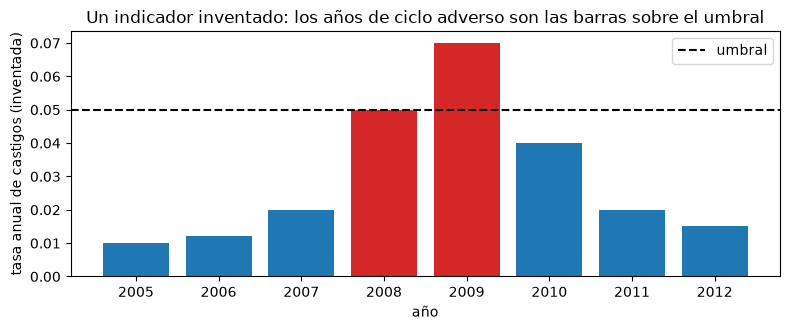

In [3]:
# Aplicar identify_downturn a un indicador inventado de ocho años y dibujar los años marcados
years = np.arange(2005, 2013)
rate = np.array([0.010, 0.012, 0.020, 0.050, 0.070, 0.040, 0.020, 0.015])
threshold = rate.mean() + 1.0 * rate.std()
flags = downturn.identify_downturn(years, rate, threshold)
print(f"umbral (media + 1 desviación estándar): {threshold:.4f}")
print("años de ciclo adverso:", years[flags].tolist())
tie = downturn.identify_downturn(np.array([2020]), np.array([0.05]), 0.05)
print("un valor igual al umbral queda marcado:", bool(tie[0]))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(years, rate, color=np.where(flags, "tab:red", "tab:blue"))
ax.axhline(threshold, color="black", linestyle="--", label="umbral")
ax.set_xlabel("año")
ax.set_ylabel("tasa anual de castigos (inventada)")
ax.set_title("Un indicador inventado: los años de ciclo adverso son las barras sobre el umbral")
ax.legend()
fig.tight_layout()
plt.show()

Dos de las ocho barras, 2008 y 2009, se elevan sobre la línea discontinua y quedan marcadas; 2010 es alta pero queda bajo ella. El umbral no es una propiedad de los datos: moverlo a la media sola marcaría 2008 a 2010, y moverlo a dos desviaciones estándar marcaría solo 2009. Por eso el motor lo trata como un parámetro de política y por eso el flujo de procesamiento de C08 declara la regla que usó. Un año exactamente en el umbral no se marca, una convención que la última línea de la celda confirma con un valor igual al umbral.

### Paso 2: el ajuste por cohortes

La LGD de ciclo adverso de C08 es el ajuste por cohortes propio de Contraste, una ilustración y no una estimación regulatoria (los textos de la EBA sobre calibración de ciclo adverso son referencias cruzadas en el motor, y el motor declara que no reclama ningún enfoque regulatorio). Dos números se definen con medias ponderadas por incumplimientos:

$$\text{largo plazo} = \frac{\sum_k n_k\,\overline{LGD}_k}{\sum_k n_k}, \qquad \text{ciclo adverso} = \frac{\sum_{k \in D} n_k\,\overline{LGD}_k}{\sum_{k \in D} n_k}, \qquad \text{ajuste} = \text{ciclo adverso} - \text{largo plazo}$$

donde $k$ recorre las seis cohortes, $\overline{LGD}_k$ es el indicador sustituto medio de la cohorte $k$, $n_k$ su número de incumplimientos y $D$ el conjunto de cohortes de ciclo adverso. (Fuente: el docstring de `downturn_add_on`.) La regla del flujo de procesamiento para $D$ es que una cohorte es de ciclo adverso cuando al menos la mitad de sus años de incumplimiento son años de ciclo adverso.

La celda siguiente lee los años, la media y el número de incumplimientos de cada cohorte desde su propia variante, aplica la regla al período del artefacto (2008 a 2011), llama a `downturn_add_on` y compara el resultado con el ajuste versionado. Se imprime cada intermedio.

In [4]:
# Marcar las cohortes de ciclo adverso con la regla de la mitad de los años y llamar a downturn_add_on
first, last = block["period"]["first_year"], block["period"]["last_year"]
cohort_lgd, weights, mask = [], [], []
print(f"{'cohort':8s} {'años':>6s} {'en el período':>14s} {'n':>8s} {'media':>9s} {'ciclo adverso':>16s}")
for c in COHORTS:
    meta = cohort[c]["outputs"]["cohort"]
    span = range(meta["first_year"], meta["last_year"] + 1)
    inside = sum(first <= y <= last for y in span)
    d = cohort[c]["outputs"]["lgd_distribution"]
    cohort_lgd.append(d["mean"]["value"])
    weights.append(d["n"])
    mask.append(inside / len(span) >= 0.5)
    print(f"{c:8s} {len(span):6d} {inside:14d} {d['n']:8,d} {d['mean']['value']:9.4f} {mask[-1]!s:>16}")

share = np.dot(weights, mask) / sum(weights)
print(f"proporción de incumplimientos en cohortes de ciclo adverso: {share:.3f}")
result = downturn.downturn_add_on(np.array(cohort_lgd), np.array(weights, float), np.array(mask))
committed = block["rows"][0]
print(f"LGD de largo plazo: {result.long_run:.6f} | LGD de ciclo adverso: {result.downturn:.6f}")
print(f"ajuste: {result.add_on:.6f}")
long_run, down = committed["long_run_lgd"]["value"], committed["downturn_lgd"]["value"]
print(f"versionado: {long_run:.6f} | {down:.6f} | {committed['add_on']:.6f}")
picked = [c for c, m in zip(COHORTS, mask) if m]
print("la regla elige las cohortes versionadas:", picked == [r["cohort_id"] for r in block["rows"]])

cohort     años  en el período        n     media    ciclo adverso
2003-06       4              0   21,919    0.7081            False
2007-08       2              1   25,299    0.8178             True
2009-10       2              2   50,281    0.8221             True
2011-13       3              1   33,673    0.7416            False
2014-19       6              0   36,481    0.6631            False
2020-23       4              0   13,930    0.7311            False
proporción de incumplimientos en cohortes de ciclo adverso: 0.416
LGD de largo plazo: 0.753873 | LGD de ciclo adverso: 0.820644
ajuste: 0.066770
versionado: 0.753873 | 0.820644 | 0.066770
la regla elige las cohortes versionadas: True


Las dos cohortes que marca la regla son 2007-08 y 2009-10, las dos con el indicador medio más alto, y las medias ponderadas dan el nivel de largo plazo, el nivel de ciclo adverso y su diferencia. La fila versionada coincide hasta seis decimales, de modo que la regla por cohortes y el `downturn_add_on` del motor son lo que produjo el artefacto. El tamaño del ajuste es modesto porque la media de largo plazo ya contiene las dos cohortes altas: las cohortes de ciclo adverso reúnen el 41,6% de los incumplimientos usados. Otro umbral marcaría otras cohortes y otro ajuste, que es la dependencia de política del paso 1 llevada hasta el final.

### Paso 3: ¿cubre la estimación la pérdida del ciclo adverso?

Una estimación que debe sostenerse en un ciclo adverso debería ser al menos la pérdida realizada en uno. `coverage_shortfall(estimate, realised)` devuelve si la estimación cubre el valor realizado y por cuánto se queda corta, con una tolerancia de $10^{-12}$: $\text{cubierta} = \text{estimación} \ge \text{realizada} - 10^{-12}$ y $\text{faltante} = \max(0, \text{realizada} - \text{estimación})$. La prueba `downturn_coverage` del motor agrega la vista por préstamo: contrasta si la LGD realizada media del ciclo adverso excede la estimación con un estadístico t unilateral sobre los préstamos de la cohorte, $t = (\overline{y} - \text{estimación}) / (s / \sqrt{n})$, y la colorea con un umbral interno de Contraste (verde cuando el valor p es al menos 0.05, ámbar desde 0.01, rojo bajo eso). Los préstamos no se versionan, así que las filas de la prueba se leen del artefacto, con la versión del motor que las horneó.

La celda aplica `coverage_shortfall` a las dos cohortes de ciclo adverso e imprime las filas de pruebas versionadas y el hallazgo que registró el flujo de procesamiento.

In [5]:
# Aplicar coverage_shortfall a las dos cohortes de ciclo adverso e imprimir las pruebas versionadas y el hallazgo
light = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}
for row in block["rows"]:
    estimate, realised = row["downturn_lgd"]["value"], row["crisis_realised_lgd"]["value"]
    covered, shortfall = downturn.coverage_shortfall(estimate, realised)
    print(f"cohorte {row['cohort_id']}: estimación {estimate:.6f} realizada {realised:.6f}"
          f" | cubierta {covered}, faltante {shortfall:.6f}")
print()
print("pruebas horneadas con riskvalidation:", cohort["2007-08"]["provenance"]["riskvalidation_version"])
for t in cohort["2007-08"]["tests"]:
    if t["test_id"] == "lgd_ead.downturn_coverage":
        stat = f"t={t['statistic']:7.4f} p={t['p_value']:.4f}"
        print(f"{t['segment']:17s} {stat} faltante={t['metric']:.6f} semáforo: {light[t['light']]}")
for f in cohort["2007-08"]["findings"]:
    if f["id"] == "F-downturn-coverage":
        print("hallazgo", f["id"], f["severity"], f["status"])

cohorte 2007-08: estimación 0.820644 realizada 0.817782 | cubierta True, faltante 0.000000
cohorte 2009-10: estimación 0.820644 realizada 0.822083 | cubierta False, faltante 0.001440

pruebas horneadas con riskvalidation: 1.0.1
cohort-2007-08    t=-1.4010 p=0.9194 faltante=0.000000 semáforo: verde
cohort-2009-10    t= 0.9655 p=0.1671 faltante=0.001440 semáforo: verde
hallazgo F-downturn-coverage S3 open


La estimación puntual queda corta respecto de la pérdida realizada de 2009-10 por una cantidad pequeña, así que el flujo de procesamiento registra un hallazgo abierto de severidad S3; la prueba no puede rechazar que la LGD realizada media esté en o bajo la estimación, así que su luz es verde. Ambas cosas son verdad: existe un faltante en la media, y es demasiado pequeño, frente a la dispersión de 50.281 indicadores sustitutos, para distinguirse estadísticamente de cero. Un validador lee las dos juntas y no las colapsa en un solo veredicto.

### Paso 4: los pisos de LGD

El marco final de Basilea III fija pisos de entrada para la LGD que puede usar un banco de enfoque avanzado, por cartera y garantía (CRE32.16 para corporativo, CRE32.58 y CRE32.59 para minorista; el módulo `floors` del motor transcribe las celdas de la investigación y marca el orden de algunas celdas minoristas NO VERIFICADO contra el texto del párrafo). `lgd_floor(portfolio, collateral)` devuelve la celda y falla para una combinación sin celda. `apply_lgd_floor(lgd, floor)` devuelve las estimaciones con piso, qué préstamos eleva el piso, la media antes y después y el aumento, $\max(\text{LGD}, \text{piso})$ préstamo a préstamo.

La primera celda pide al motor el piso de cada celda de cartera y garantía de la tabla del artefacto C08 y los imprime con sus referencias de párrafo. La segunda aplica el piso corporativo sin garantía de 25% a ocho LGD **inventadas**, una mezcla de valores bajos y altos, y dibuja lo que hace un piso que opera.

In [6]:
# Pedir al motor el piso de cada celda de la tabla del artefacto e imprimirlo con su párrafo
cells = models["fit"]["floors"]["cells"]
portfolio = {"corporate": "corporativo", "retail": "minorista"}
collateral = {"unsecured": "sin garantía", "financial": "financiera", "receivables": "cuentas por cobrar",
              "real-estate": "bienes raíces", "other-physical": "otra física", "mortgage": "hipotecaria",
              "qrre": "rotativa calificada (QRRE)"}
for cell in cells:
    kind, security = cell["portfolio"], cell["collateral"]
    floor = floors.lgd_floor(kind, security)
    print(f"{portfolio[kind]:12s} {collateral[security]:28s} piso {floor:.2f}  ({cell['reference']})")

corporativo  sin garantía                 piso 0.25  (CRE32.16)
corporativo  financiera                   piso 0.00  (CRE32.16)
corporativo  cuentas por cobrar           piso 0.10  (CRE32.16)
corporativo  bienes raíces                piso 0.10  (CRE32.16)
corporativo  otra física                  piso 0.15  (CRE32.16)
minorista    hipotecaria                  piso 0.05  (CRE32.58 to CRE32.59)
minorista    rotativa calificada (QRRE)   piso 0.50  (CRE32.58 to CRE32.59)
minorista    sin garantía                 piso 0.30  (CRE32.58 to CRE32.59)
minorista    financiera                   piso 0.00  (CRE32.58 to CRE32.59)
minorista    cuentas por cobrar           piso 0.10  (CRE32.58 to CRE32.59)
minorista    bienes raíces                piso 0.10  (CRE32.58 to CRE32.59)
minorista    otra física                  piso 0.15  (CRE32.58 to CRE32.59)


La segunda celda, de abajo, es el efecto de un piso sobre un conjunto pequeño de números.

el piso opera sobre 4 de 8 | proporción 0.500
media antes 0.3412 | media después 0.4062 | aumento 0.0650


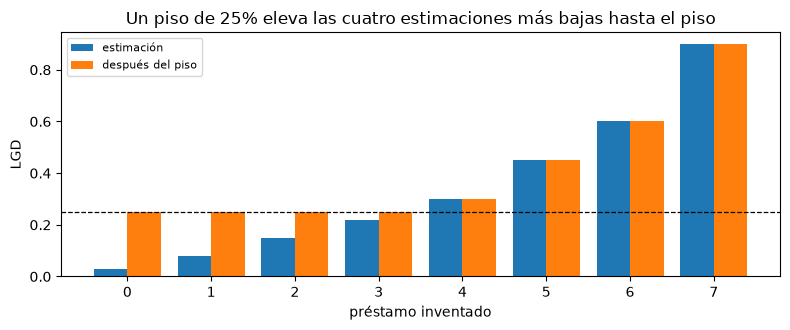

In [7]:
# Aplicar un piso de 25% a ocho LGD inventadas y dibujarlas antes y después
invented = np.array([0.03, 0.08, 0.15, 0.22, 0.30, 0.45, 0.60, 0.90])
bite = floors.apply_lgd_floor(invented, floors.lgd_floor("corporate", "unsecured"))
print(f"el piso opera sobre {int(bite.binding.sum())} de {invented.size} | proporción {bite.share_binding:.3f}")
print(f"media antes {bite.mean_before:.4f} | media después {bite.mean_after:.4f} | aumento {bite.uplift:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.4))
positions = np.arange(invented.size)
ax.bar(positions - 0.2, invented, width=0.4, color="tab:blue", label="estimación")
ax.bar(positions + 0.2, bite.applied, width=0.4, color="tab:orange", label="después del piso")
ax.axhline(0.25, color="black", linestyle="--", linewidth=0.9)
ax.set_xticks(positions)
ax.set_xlabel("préstamo inventado")
ax.set_ylabel("LGD")
ax.set_title("Un piso de 25% eleva las cuatro estimaciones más bajas hasta el piso")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las cuatro estimaciones bajo 0,25 se elevan hasta la línea discontinua y las cuatro sobre ella no se tocan, de modo que la media pasa de 0,3412 a 0,4062. Un piso es entonces una cota inferior, y su efecto depende por completo de cuánta cartera queda debajo: aquí la mitad, porque los ocho valores se inventaron para quedar a ambos lados del piso. Las carteras reales de más abajo no, que es el hallazgo del paso siguiente.

### Paso 5: dónde muerde el piso de LGD en C08

El artefacto C08 aplica los pisos a las predicciones del logit fraccional de cada cohorte, por segmento (`outputs.floors_bite`). El archivo SBA no tiene un campo de garantía, así que el flujo de procesamiento infiere la garantía desde el plazo y el carácter rotativo (líneas y préstamos de hasta 7 años como sin garantía, de 7 a 20 años como otra física, de 20 años o más como inmobiliaria), como dice la nota del propio artefacto; el piso de cada segmento se sigue de ahí. El efecto es el alza media. La celda imprime las tablas de 2007-08 y 2009-10 y dibuja la LGD predicha media de cada segmento frente a su piso.

sme-revolver         corporate-unsecured        piso 0.25  n= 7,864 media antes 0.8903  proporción que opera 0.000 aumento 0.0000
sme-term-up-to-84    corporate-unsecured        piso 0.25  n=14,454 media antes 0.7254  proporción que opera 0.000 aumento 0.0000
sme-term-85-239      corporate-other-physical   piso 0.15  n= 2,739 media antes 0.6270  proporción que opera 0.000 aumento 0.0000
sme-term-240-plus    corporate-real-estate      piso 0.10  n=   242 media antes 0.6017  proporción que opera 0.000 aumento 0.0000
2009-10: mayor proporción que opera 0.0


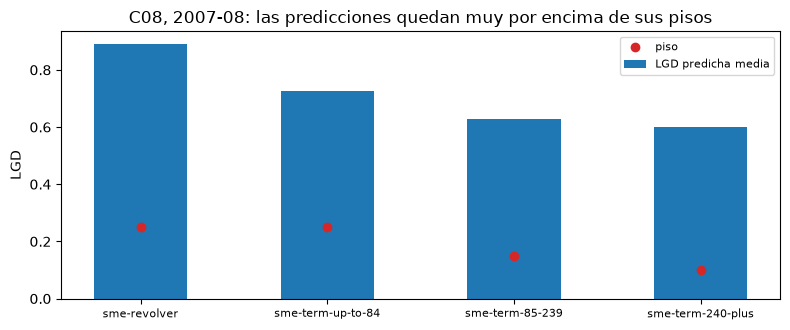

In [8]:
# Imprimir la tabla floors_bite versionada y dibujar la predicción media de cada segmento contra su piso
rows = cohort["2007-08"]["outputs"]["floors_bite"]["rows"]
for r in rows:
    head = f"{r['segment_id']:20s} {r['floor_id']:26s} piso {r['floor']:.2f}  n={r['n']:6,d}"
    tail = f"media antes {r['mean_before']['value']:.4f}  proporción que opera {r['share_binding']:.3f}"
    print(head, tail, f"aumento {r['uplift']:.4f}")
rows_2 = cohort["2009-10"]["outputs"]["floors_bite"]["rows"]
print("2009-10: mayor proporción que opera", max(r["share_binding"] for r in rows_2))

fig, ax = plt.subplots(figsize=(8, 3.4))
positions = np.arange(len(rows))
ax.bar(positions, [r["mean_before"]["value"] for r in rows], width=0.5, color="tab:blue", label="LGD predicha media")
ax.scatter(positions, [r["floor"] for r in rows], color="tab:red", zorder=3, label="piso")
ax.set_xticks(positions)
ax.set_xticklabels([r["segment_id"] for r in rows], fontsize=8)
ax.set_ylabel("LGD")
ax.set_title("C08, 2007-08: las predicciones quedan muy por encima de sus pisos")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Cada barra queda muy por encima de su marcador rojo: la LGD predicha media de los segmentos de C08 va de 0,6017 a 0,8903 mientras los pisos son de 0,10 a 0,25, así que la proporción de préstamos donde opera el piso es cero en 2007-08, y la celda imprime el mismo cero como la mayor proporción de 2009-10. El indicador de castigos tiene valores altos por construcción, porque es la parte castigada de un monto aprobado. Un piso pensado para una cartera hipotecaria con LGD de 10 a 20% importaría ahí; en esta cartera nunca opera, y la figura muestra por qué las tablas de pisos de este paso son una verificación barata de correr y que rara vez opera.

### Paso 6: el piso de EAD

El piso de EAD del mismo marco (CRE32.36 para corporativo, CRE32.64 para minorista) dice "el monto en balance más 50% de la exposición fuera de balance usando el CCF estandarizado". La fórmula del motor es $\text{piso} = E + s\,c\,\max(L - E, 0)$ con $s$ la parte fuera de balance (0.5) y $c$ el factor de conversión supervisor de la clase de línea, que devuelve `supervisory_ccf(item)` (por ejemplo 0.4 para compromisos, CRE20.98, y 0.1 para líneas cancelables sin condiciones, CRE20.100). La lectura de que el 50% se aplica a la exposición fuera de balance ponderada por el CCF sigue la redacción de la investigación y el motor la marca NO VERIFICADA contra el texto del párrafo. Una línea sobregirada no tiene monto fuera de balance, así que su piso es su monto utilizado. `apply_ead_floor(ead, floor)` toma el máximo elemento a elemento.

La celda lista los cinco factores supervisores, aplica el piso a tres líneas **inventadas** (una de ellas sobregirada), y luego lee lo que informa el artefacto C09 para la misma regla sobre las líneas de su generador.

In [9]:
# Listar los CCF supervisores, aplicar el piso de EAD a tres facilidades inventadas y leer el bloque de pisos de C09
item = {"direct-credit-substitutes": "sustitutos directos de crédito",
        "nifs-rufs-transaction-related-contingents": "NIF, RUF y contingentes de transacción",
        "commitments": "compromisos",
        "short-term-self-liquidating-trade-letters-of-credit": "cartas de crédito comercial a corto plazo",
        "unconditionally-cancellable": "cancelables sin condiciones"}
for name in floors.SUPERVISORY_CCF:
    print(f"{item[name]:56s} {floors.supervisory_ccf(name):.1f}")
drawn = np.array([20.0, 60.0, 110.0])
limit = np.array([100.0, 100.0, 100.0])
sa_ccf = np.full(3, floors.supervisory_ccf("commitments"))
floor_ead = floors.ead_floor(drawn, limit, sa_ccf)
estimate = np.array([40.0, 70.0, 105.0])
bite_ead = floors.apply_ead_floor(estimate, floor_ead)
print("girado:", drawn, "| límite:", limit)
print("piso de EAD:", floor_ead, "| estimaciones inventadas:", estimate, "| después del piso:", bite_ead.applied)
print(f"el piso opera sobre {int(bite_ead.binding.sum())} de {estimate.size}")
eadf = level3["outputs"]["ead_floor"]
for r in eadf["rows"]:
    label = item[r["facility_class"]]
    head = f"C09 {label:44s} CCF {r['sa_ccf']:.1f} ({r['reference']}) n={r['n']:,}"
    print(head, f"proporción que opera {r['share_binding']:.3f}")

sustitutos directos de crédito                           1.0
NIF, RUF y contingentes de transacción                   0.5
compromisos                                              0.4
cartas de crédito comercial a corto plazo                0.2
cancelables sin condiciones                              0.1
girado: [ 20.  60. 110.] | límite: [100. 100. 100.]
piso de EAD: [ 36.  68. 110.] | estimaciones inventadas: [ 40.  70. 105.] | después del piso: [ 40.  70. 110.]
el piso opera sobre 1 de 3
C09 cancelables sin condiciones                  CCF 0.1 (CRE20.100) n=38,817 proporción que opera 0.000
C09 compromisos                                  CCF 0.4 (CRE20.98) n=38,817 proporción que opera 0.000


## Resultados

**Respuesta:** La regla marca 2008 a 2011 y elige las cohortes 2007-08 y 2009-10, que reúnen el 41,6% de los incumplimientos; el ajuste por cohortes es 0,066770 sobre una LGD de largo plazo de 0,753873, una LGD de ciclo adverso de 0,820644 que cubre el 0,817782 realizado de 2007-08 y queda corta en 0,001440 frente a 2009-10. Los pisos de Basilea no operan sobre estas carteras: la LGD predicha media de los segmentos de C08 va de 0,6017 a 0,8903 frente a pisos de 0,10 a 0,25, y el piso de EAD no opera sobre ninguna de las 38.817 líneas en incumplimiento de C09, mientras que en ocho LGD inventadas un piso de 25% opera sobre 4 y sube la media de 0,3412 a 0,4062.

- **El umbral es una elección de política.** En el indicador inventado el umbral (media más una desviación estándar) es 0,0498, y solo 2008 y 2009 quedan sobre él; un valor exactamente en el umbral no se marca.
- **El ajuste se reproduce.** Con el período real de 2008 a 2011, la regla de la mitad de los años elige las cohortes 2007-08 (uno de sus dos años dentro del período) y 2009-10 (ambos). `downturn_add_on` da una LGD de largo plazo de 0,753873, una LGD de ciclo adverso de 0,820644 y un ajuste de 0,066770, iguales a la fila versionada hasta seis decimales. El ajuste es una diferencia de dos medias de un indicador, no una estimación regulatoria.
- **Una prueba verde y un hallazgo abierto conviven.** La estimación cubre la pérdida realizada de 2007-08 y queda corta frente a 2009-10 en 0,001440. Las pruebas `downturn_coverage` están en verde en ambas (valores p de 0,9194 y 0,1671), y el flujo de procesamiento mantiene el hallazgo abierto con severidad S3: el faltante existe en la media y es pequeño frente a la dispersión de 50.281 préstamos.
- **Los pisos son una tabla que el motor responde.** `lgd_floor` devuelve un piso para cada una de las 12 celdas de la tabla del artefacto, desde 0,00 para garantía financiera hasta 0,50 para exposiciones minoristas rotativas calificadas. En ocho LGD inventadas el piso de 25% opera sobre cuatro y sube la media en 0,0650.
- **En C08 y C09 ningún piso opera.** Todo segmento de C08 muestra una proporción que opera de 0,000 en 2007-08 y en 2009-10, y el piso de EAD de C09 no opera sobre ninguna de las 38.817 líneas en incumplimiento con ninguno de los dos factores supervisores. El ejemplo inventado de EAD sí opera sobre una línea de tres, la sobregirada, cuyo piso es su monto girado de 110.

Lo que el notebook no hace: no estima una LGD de ciclo adverso para un regulador ni valida un piso. El indicador tiene valores altos por construcción, así que un piso que importa en una cartera hipotecaria de LGD baja no importa aquí; los ejemplos inventados existen para mostrar la aritmética donde sí importa. El notebook siguiente mide el sesgo de los estimadores del CCF contra la verdad conocida de C09.

## Resumen

- `identify_downturn` marca los años cuyo indicador está estrictamente sobre un umbral que es un parámetro de política; el flujo de procesamiento de C08 toma la media más una desviación estándar de la propia tasa anual de castigos de la cartera y la racha más larga de años marcados.
- El ajuste por cohortes es una diferencia de medias ponderadas por incumplimientos, `downturn_add_on`; reproduce las filas versionadas una vez que la regla de la mitad de los años elige las cohortes. Es una ilustración, no una estimación regulatoria.
- La cobertura se juzga sobre la estimación puntual (`coverage_shortfall`) y sobre los préstamos (`downturn_coverage`); las dos pueden diferir, y ambas se informan.
- Los pisos de LGD son una tabla por cartera y garantía (`lgd_floor`, `apply_lgd_floor`) y el piso de EAD es el monto utilizado más la mitad del monto no utilizado ponderado por el CCF (`ead_floor`, `apply_ead_floor`). En C08 y C09 ningún piso muerde.

**Qué probar a continuación.** Baja las estimaciones de EAD inventadas del paso 6 y mira cómo el piso empieza a morder; aplica el piso minorista hipotecario de 5% a un conjunto de LGD bajas. Luego sigue con el notebook 05, que mide cómo la elección de la fecha de referencia sesga el CCF.

## Referencias

- BCBS, Basel Framework, CRE32 (enfoque de calificaciones internas; los pisos de entrada de LGD, CRE32.16 y CRE32.58 a CRE32.59, y el piso de EAD, CRE32.36 y CRE32.64, como los transcribe el módulo `floors` del motor). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- EBA/RTS/2018/04 y EBA/GL/2019/03 sobre la estimación de ciclo adverso: solo referencias cruzadas en el módulo `downturn` del motor, que declara que el ajuste es el cohortal de Contraste y no reclama ningún enfoque regulatorio.
- La documentación del propio motor: `riskvalidation.lgd_ead.downturn` y `riskvalidation.lgd_ead.floors` (versión 0.8.1).
- Este repositorio: `docs/design/SDD.md` (casos C08 y C09), `data-flujo de procesamiento/flujo de procesamiento/cases/c08/downturn.py` (la regla de las cohortes de ciclo adverso) y `data/derived/C08/`, `data/derived/C09/level-3.json`.